# 3.12 Dimensionality Reduction

## Data Loading and Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score 
from sklearn.cluster import DBSCAN

##### **Iris** preprocessing

In [2]:
iris = sns.load_dataset('iris')
X_iris = iris.drop(columns=['species'])
y_iris = iris['species']

# Standardize the continuous features
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

##### **Tips** preprocessing

In [3]:
tips = sns.load_dataset('tips').dropna()

# Removing the categorical features from the tips dataset
X_tips = tips[['total_bill', 'tip', 'size']]
y_tips = tips['sex']

# Standardise the continuous features
scaler_tips = StandardScaler()
X_tips_scaled = scaler_tips.fit_transform(X_tips)

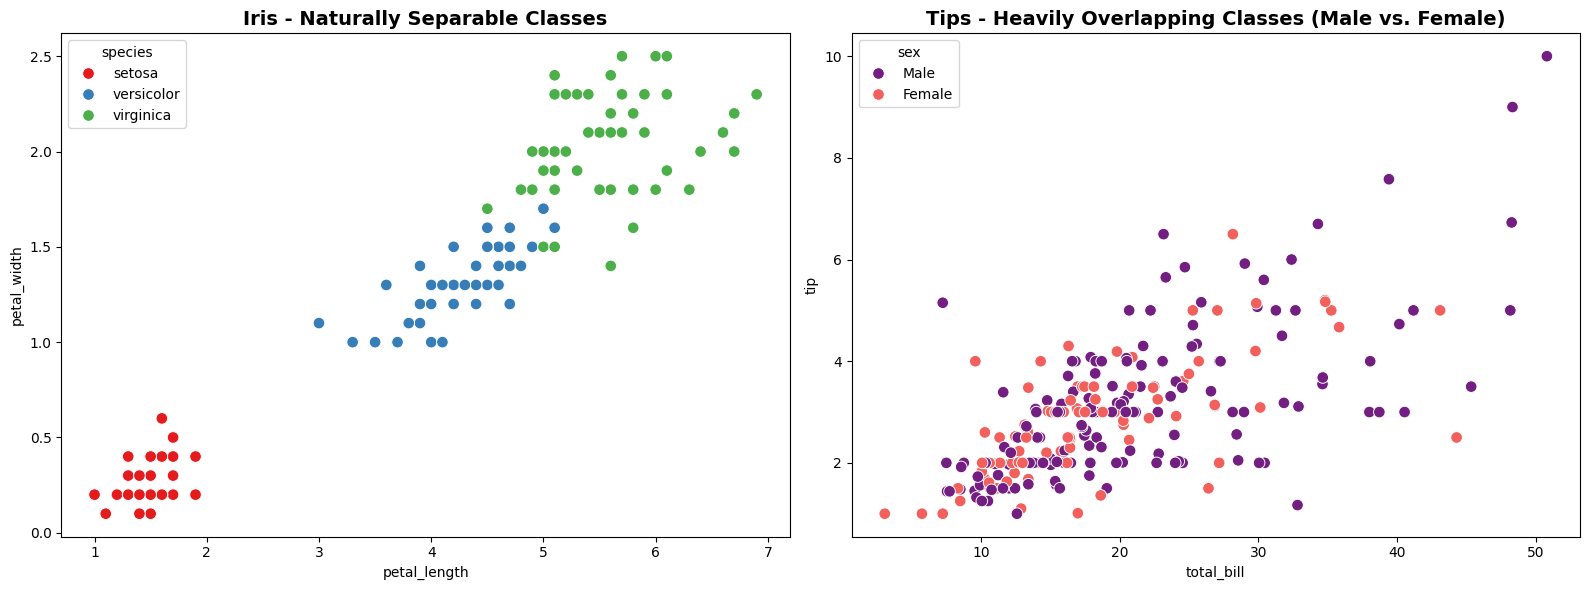

In [4]:
fig = plt.figure(figsize=(16, 6))

# Iris
ax1 = fig.add_subplot(121)
sns.scatterplot(data=iris, x='petal_length', y='petal_width', hue='species', palette='Set1', ax=ax1, s=70)
ax1.set_title("Iris - Naturally Separable Classes", fontweight='bold', fontsize=14)

# Tips
ax2 = fig.add_subplot(122)
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex', palette='magma', ax=ax2, s=70)
ax2.set_title("Tips - Heavily Overlapping Classes (Male vs. Female)", fontweight='bold', fontsize=14)

plt.tight_layout()
plt.show()

### **Task 1**

## PCA - Principle Component Analysis

Standard PCA is a linear method. It assumes that the variance in your data can be captured by drawing straight, orthogonal axes through it. PCA is also unsupervised, so it doesn't know our target labels, like Species or Sex. It simply looks for the direction where the data spreads out the most.

PCA simulator - https://numiqo.com/lab/pca

PCA from scratch: https://drscotthawley.github.io/blog/posts/2019-12-21-pca-from-scratch.html

In [5]:
from sklearn.decomposition import PCA

By leaving PCA() empty (n_components=None), we force the algorithm to calculate the variance for ALL available dimensions.

In [6]:
pca_iris_full = PCA().fit(X_iris_scaled)
pca_tips_full = PCA().fit(X_tips_scaled)

`explained_variance_ratio_` returns an array representing the percentage of total variance captured by each principal component.

`np.cumsum` calculates the running total (Cumulative Variance)

In [7]:
iris_ind_var = pca_iris_full.explained_variance_ratio_
iris_cum_var = np.cumsum(iris_ind_var)

tips_ind_var = pca_tips_full.explained_variance_ratio_
tips_cum_var = np.cumsum(tips_ind_var)

**Scree plots**

The Scree Plot is a tool we use to check our data. It shows how much of the dataset’s total information, or variance, each new axis explains.

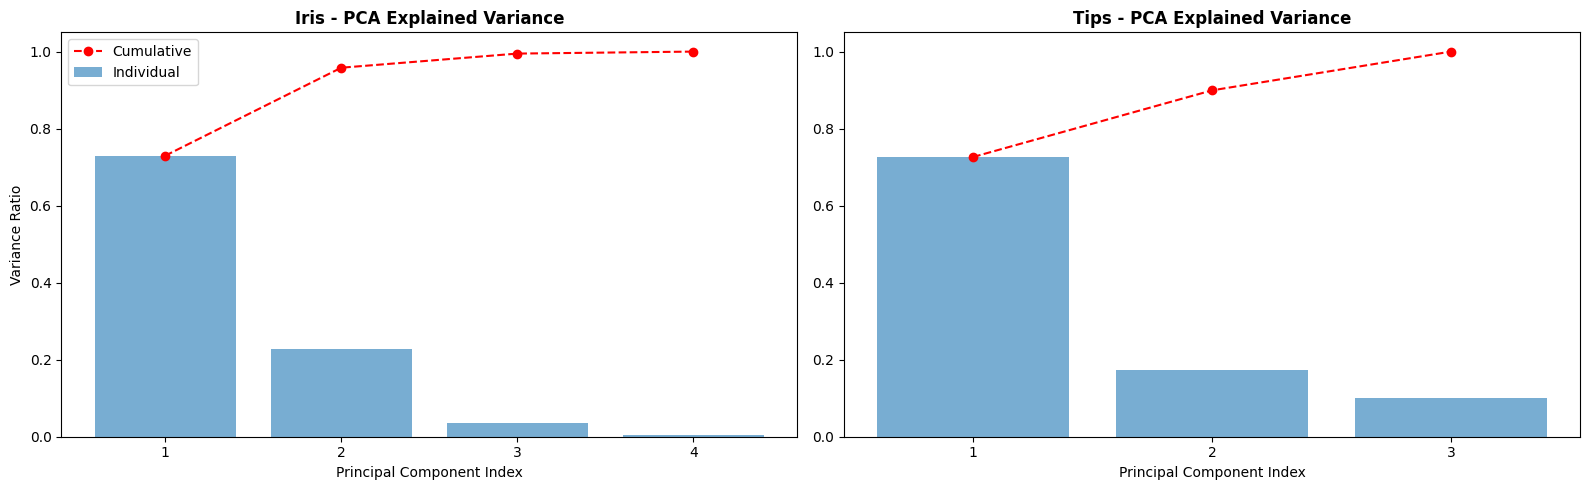

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Iris
axes[0].bar(range(1, len(iris_ind_var) + 1), iris_ind_var, alpha=0.6, label='Individual')
axes[0].plot(range(1, len(iris_ind_var) + 1), iris_cum_var, marker='o', linestyle='--', color='red', label='Cumulative')
axes[0].set_title('Iris - PCA Explained Variance', fontweight='bold')
axes[0].set_xlabel('Principal Component Index')
axes[0].set_ylabel('Variance Ratio')
axes[0].set_xticks(range(1, len(iris_ind_var) + 1))
axes[0].legend()

# Plot Tips
axes[1].bar(range(1, len(tips_ind_var) + 1), tips_ind_var, alpha=0.6, label='Individual')
axes[1].plot(range(1, len(tips_ind_var) + 1), tips_cum_var, marker='o', linestyle='--', color='red', label='Cumulative')
axes[1].set_title('Tips - PCA Explained Variance', fontweight='bold')
axes[1].set_xlabel('Principal Component Index')
axes[1].set_xticks(range(1, len(tips_ind_var) + 1))

plt.tight_layout()
plt.show()

Look at the shape of the cumulative variance line (the red dashed line) on both graphs.

* In the Iris Dataset (on the left), PC1 by itself captures more than 70% of the variance.
* For the Tips Dataset (on the right), PC1 also captures about 70% of the variance.

Since PC1 captures most of the variance in both datasets, will it also separate the classes (Species or Sex)? To answer this, we need to project the data into two dimensions.

We restrict the algorithm to only generate the top 2 orthogonal axes.

In [9]:
pca_2d = PCA(n_components=2)
X_iris_pca = pca_2d.fit_transform(X_iris_scaled)
X_tips_pca = pca_2d.fit_transform(X_tips_scaled)

In [10]:
X_iris_pca

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,

The Scree Plot showed that PC1 and PC2 capture most of the variance in our data. So, we drop the other dimensions and map the data points onto these two main axes.

We colour the dots by target labels, such as species and sex. Since PCA is unsupervised, it did not use these labels to create the axes. We add the colors afterward to check if the directions of greatest variance match our business categories.

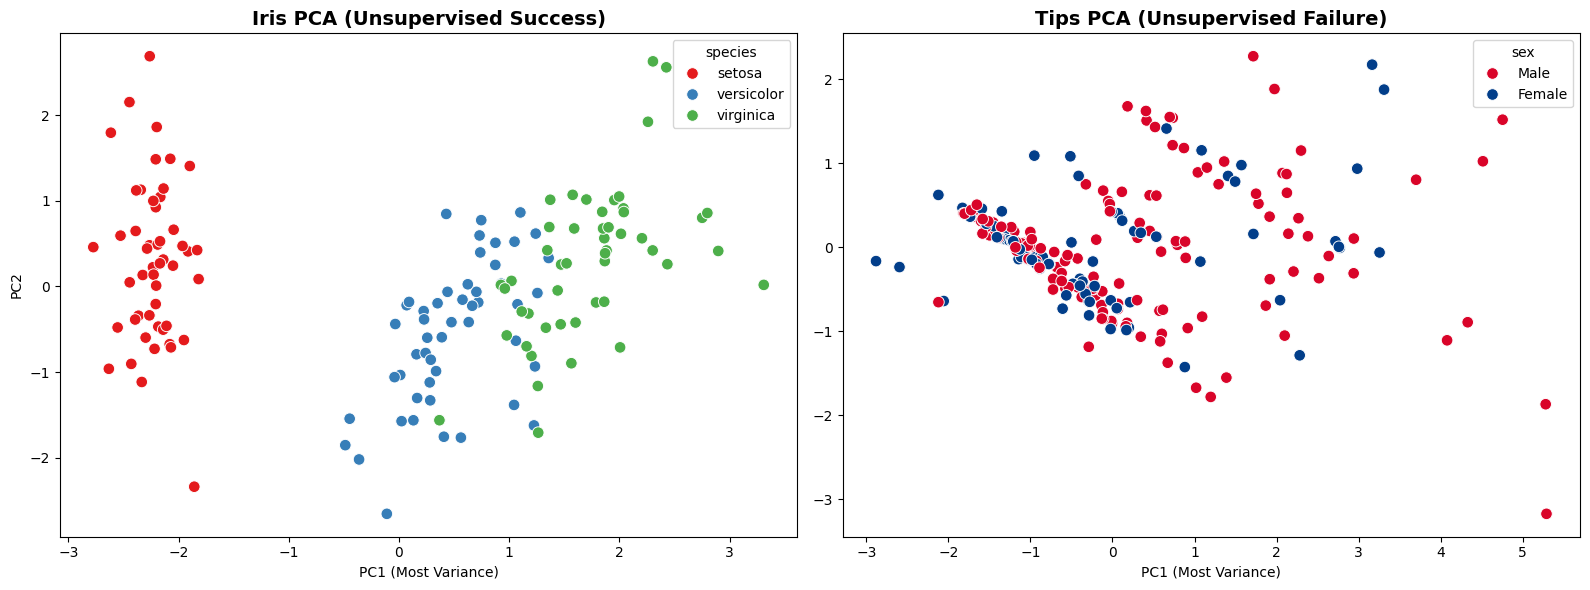

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Iris
sns.scatterplot(x=X_iris_pca[:, 0], y=X_iris_pca[:, 1], hue=y_iris, ax=axes[0], palette='Set1', s=70)
axes[0].set_title("Iris PCA (Unsupervised Success)", fontweight='bold', fontsize=14)
axes[0].set_xlabel("PC1 (Most Variance)")
axes[0].set_ylabel("PC2")

# Plot Tips
sns.scatterplot(x=X_tips_pca[:, 0], y=X_tips_pca[:, 1], hue=y_tips, ax=axes[1], palette=['#d90429', '#023e8a'], s=70)
axes[1].set_title("Tips PCA (Unsupervised Failure)", fontweight='bold', fontsize=14)
axes[1].set_xlabel("PC1 (Most Variance)")

plt.tight_layout()
plt.show()


Notice the clear difference between these two geometric situations.

* iris - Here, the unsupervised method worked well. The natural differences in flower petals made it easy to separate the species. 
* tips - In this case, the unsupervised method did not work. The Scree Plot showed that PC1 explained 70% of the variance, but if you look at the dots on the PC1 axis, male and female spenders are completely mixed together.

PCA found the axis where total spending changed the most, but men and women spend money in very similar, overlapping ways. To separate these groups, we need to use a supervised algorithm that understands the labels.

## LDA - Linear Discriminant Analysis - as a Dimensionality Reduction and Classifier model

Before applying LDA to reduce our data, we need to set a mathematical baseline. We'll train a standard Logistic Regression model using all the available features—4 for Iris and 3 for Tips.

We do this to follow an important rule in dimensionality reduction: **if reducing dimensions ruins your predictive power, the algorithm is not good**. Next, LDA will reduce these features to 2D and 1D, but it should keep the classification accuracy we set now.

### Train a baseline - Logistic Regression

In [12]:
# Iris
X_ir_train, X_ir_test, y_ir_train, y_ir_test = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42)

scaler_ir = StandardScaler().fit(X_ir_train)
X_ir_train_sc = scaler_ir.transform(X_ir_train)
X_ir_test_sc = scaler_ir.transform(X_ir_test)

# Tips
X_tp_train, X_tp_test, y_tp_train, y_tp_test = train_test_split(X_tips, y_tips, test_size=0.3, random_state=42)

scaler_tp = StandardScaler().fit(X_tp_train)
X_tp_train_sc = scaler_tp.transform(X_tp_train)
X_tp_test_sc = scaler_tp.transform(X_tp_test)

In [13]:
lr_iris = LogisticRegression().fit(X_ir_train_sc, y_ir_train)
lr_tips = LogisticRegression().fit(X_tp_train_sc, y_tp_train)

In [14]:
iris_base_f1 = f1_score(y_ir_test, lr_iris.predict(X_ir_test_sc), average='macro')
tips_base_f1 = f1_score(y_tp_test, lr_tips.predict(X_tp_test_sc), average='macro')

In [15]:
print(f"Iris Base F1 Score: {iris_base_f1:.4f}")
print(f"Tips Base F1 Score: {tips_base_f1:.4f}")

Iris Base F1 Score: 1.0000
Tips Base F1 Score: 0.4401


### LDA

Unlike PCA, which just looks for variance, Linear Discriminant Analysis (LDA) is supervised. It uses our target labels (y_train) to find a boundary that separates different classes as much as possible while keeping each class close together.

Because it is supervised, LDA is bound by a strict mathematical limit: the C - 1 Rule. LDA can only project data into a maximum of C - 1 dimensions, where C is the number of target classes.

* Iris: 3 species - 1 = 2 Dimensions.
* Tips: 2 sexes - 1 = 1 Dimension.

We will use LDA to classify the test data directly to check if reducing dimensions affects our ability to predict. 

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

We explicitly set n_components based on the C-1 rule.

In [17]:
lda_iris = LDA(n_components=2).fit(X_ir_train_sc, y_ir_train)
lda_tips = LDA(n_components=1).fit(X_tp_train_sc, y_tp_train)

LDA has a built-in .predict() method.

In [18]:
iris_lda_f1 = f1_score(y_ir_test, lda_iris.predict(X_ir_test_sc), average='macro')
tips_lda_f1 = f1_score(y_tp_test, lda_tips.predict(X_tp_test_sc), average='macro')

In [19]:
print(f"Iris LDA F1 Score: {iris_lda_f1:.4f}")
print(f"Tips LDA F1 Score: {tips_lda_f1:.4f}")

Iris LDA F1 Score: 1.0000
Tips LDA F1 Score: 0.4401


We have achieved the same scores as Logistic Regression. This shows that LDA found the best mathematical angle for this data. However, for the Tips dataset, the "best" angle still yields a very low score of 0.44.

We use .transform() to physically project the high-dimensional data down onto the new LDA axes so we can plot it in the next step.

In [20]:
X_ir_test_lda = lda_iris.transform(X_ir_test_sc)
X_tp_test_lda = lda_tips.transform(X_tp_test_sc)

In [21]:
X_ir_train_lda = lda_iris.transform(X_ir_train_sc)
X_tp_train_lda = lda_tips.transform(X_tp_train_sc)

Visualising test and train data

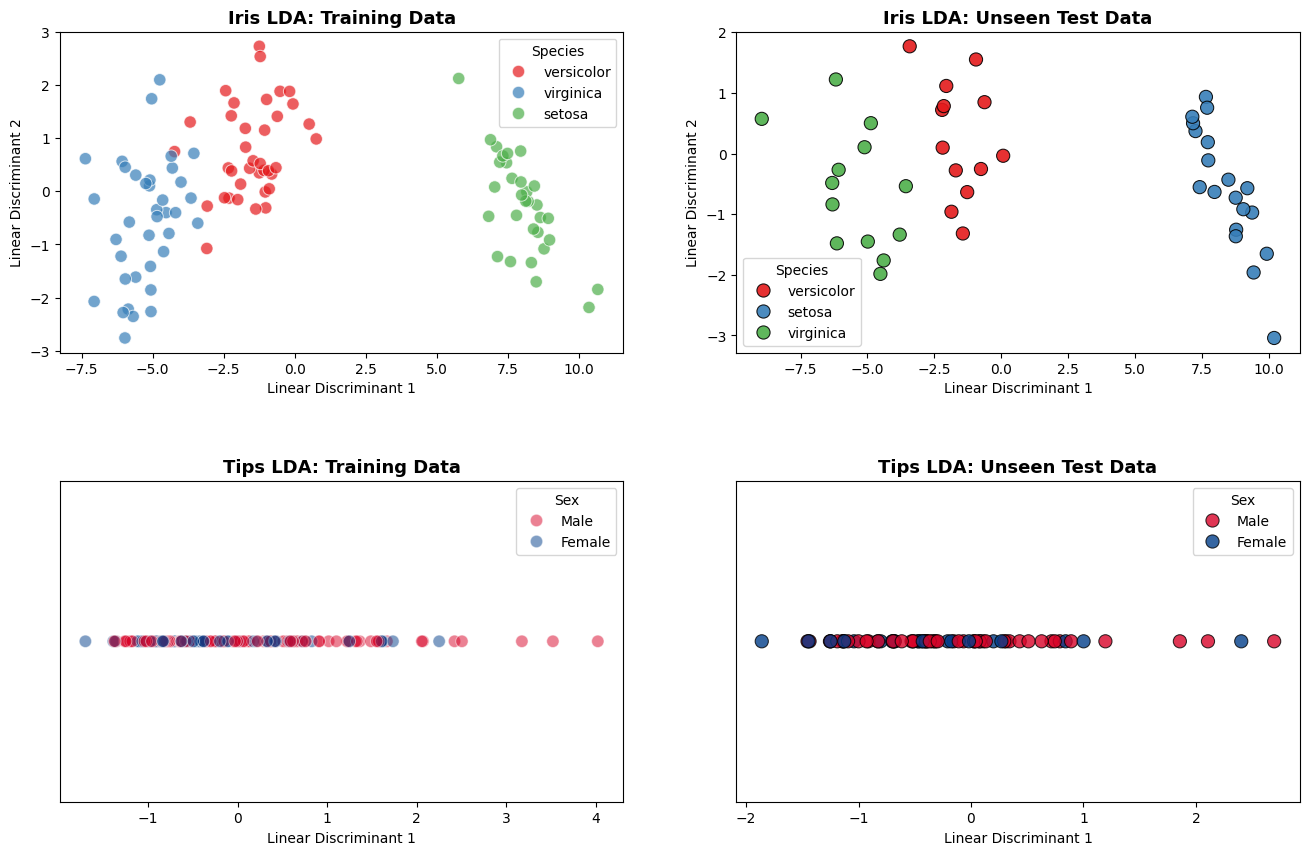

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plt.subplots_adjust(hspace=0.4) 

# Iris Training Data
sns.scatterplot(
    x=X_ir_train_lda[:, 0], y=X_ir_train_lda[:, 1], 
    hue=y_ir_train, ax=axes[0, 0], palette='Set1', s=80, alpha=0.7
)
axes[0, 0].set_title("Iris LDA: Training Data", fontweight='bold', fontsize=13)
axes[0, 0].set_xlabel("Linear Discriminant 1")
axes[0, 0].set_ylabel("Linear Discriminant 2")
axes[0, 0].legend(title='Species')

# Iris Test Data
sns.scatterplot(
    x=X_ir_test_lda[:, 0], y=X_ir_test_lda[:, 1], 
    hue=y_ir_test, ax=axes[0, 1], palette='Set1', s=90, alpha=0.9, edgecolor='black'
)
axes[0, 1].set_title("Iris LDA: Unseen Test Data", fontweight='bold', fontsize=13)
axes[0, 1].set_xlabel("Linear Discriminant 1")
axes[0, 1].set_ylabel("Linear Discriminant 2")
axes[0, 1].legend(title='Species')



tips_palette = ['#d90429', '#023e8a'] 

# Tips Training Data
sns.scatterplot(
    x=X_tp_train_lda[:, 0], y=np.zeros_like(X_tp_train_lda[:, 0]), 
    hue=y_tp_train, ax=axes[1, 0], palette=tips_palette, s=80, alpha=0.5
)
axes[1, 0].set_title("Tips LDA: Training Data", fontweight='bold', fontsize=13)
axes[1, 0].set_xlabel("Linear Discriminant 1")
axes[1, 0].set_yticks([]) # Hide Y axis
axes[1, 0].legend(title='Sex')

# Tips Test Data
sns.scatterplot(
    x=X_tp_test_lda[:, 0], y=np.zeros_like(X_tp_test_lda[:, 0]), 
    hue=y_tp_test, ax=axes[1, 1], palette=tips_palette, s=90, alpha=0.8, edgecolor='black'
)
axes[1, 1].set_title("Tips LDA: Unseen Test Data", fontweight='bold', fontsize=13)
axes[1, 1].set_xlabel("Linear Discriminant 1")
axes[1, 1].set_yticks([]) # Hide Y axis
axes[1, 1].legend(title='Sex')

plt.show()

Notice that the Tips dataset (bottom row) has no Y-axis. This shows the C-1 rule at work. Since there are only two classes (Male and Female), LDA squeezed the data into a single number line. In other words, all the dots are on a flat plane.

* Now look at the top row. The Iris Test data looks almost the same as the Training data. The algorithm generalised well.
* Now look at the bottom row. Even though the model knew the exact answers during training, LDA could not draw a straight line to separate men from women. The Test data shows the same problem.

This is the main lesson with linear models: linear math cannot fix bad features. If men and women tip in the same overlapping ways, a straight line won't help separate them. To separate this data, we need to move beyond straight lines and use probabilistic manifolds.

### **Task 3**

## t-SNE

Linear models like PCA and LDA search for straight lines throughout the dataset. t-SNE takes a different approach and does not use straight lines at all. Instead, it turns Euclidean distances into conditional probabilities. It asks, **"What is the probability that point A would pick point B as its neighbour?"**

Since t-SNE focuses only on local neighbours, it is considered a Manifold Algorithm. It helps reveal complex data patterns, similar to untangling a ball of yarn. However, t-SNE is very sensitive to the perplexity parameter, which controls how many neighbours the algorithm considers when making its map. We will try three different perplexity levels to see how the topology changes.

In [23]:
from sklearn.manifold import TSNE

- **n_components** - specifies the dimension of the final, low-dimensional space for projection.
- **perplexity** - relates to the effective number of local neighbors considered for each data point. It is a mathematical measure of the smoothness of density distribution (the conditional probability that data point "i" would pick data point "j" as its neighbour based on the high-dimensional distance between "i" and "j").
    - **low** perplexity(5) - t-SNE prioritises very local relationships, often resulting in fragmented, small, tightly packed clusters that may represent noise rather than true structure.
    -  **high** perplexity(50) - t-SNE considers broader relationships, leading to more generalised and cohesive clusters that reveal the global organisation of the data.
- **learning_rate** - controls the magnitude of the step taken during the gradient descent optimisation process.
    - **too low** learning_rate - the optimisation process will be extremely slow, potentially getting stuck in a local minimum, resulting in a suboptimal visualisation
    - **too high** learning_rate - the optimisation process will overshoot the minimum, causing points to fly out or "explode", resulting in a messy, unstable cloud of points.
      
"auto" - will use N/perplexity, but the common values for manual tuning are between 10 and 1000.

In [24]:
perplexities = [5, 30, 50]

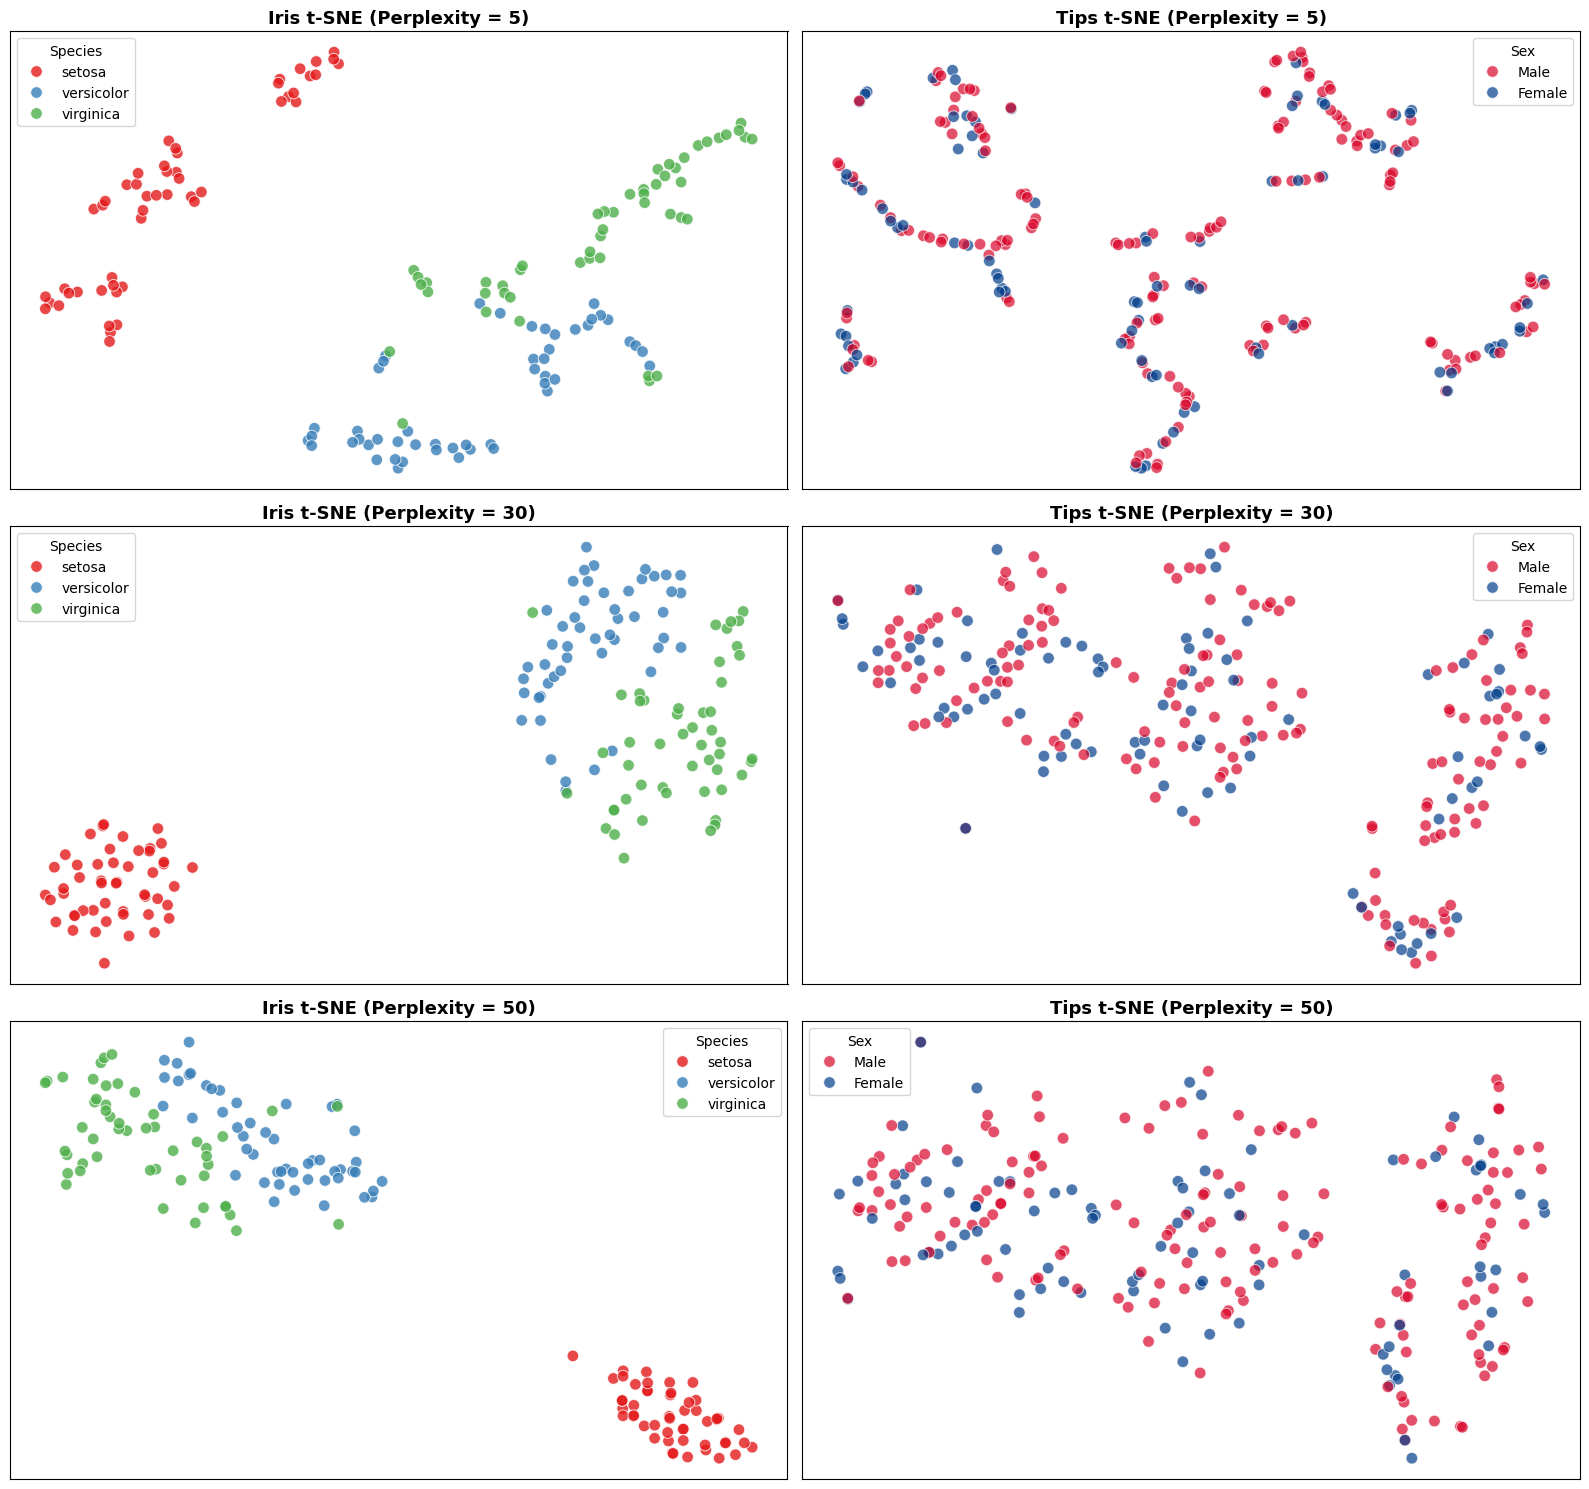

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
plt.subplots_adjust(hspace=0.3)

for i, p in enumerate(perplexities):
    # 1. Fit Manifolds
    tsne_iris = TSNE(n_components=2, perplexity=p, random_state=42)
    X_ir_tsne = tsne_iris.fit_transform(X_iris_scaled)
    
    tsne_tips = TSNE(n_components=2, perplexity=p, random_state=42)
    X_tp_tsne = tsne_tips.fit_transform(X_tips_scaled)
    
    # 2. Plot Iris 
    sns.scatterplot(
        x=X_ir_tsne[:, 0], y=X_ir_tsne[:, 1], 
        hue=y_iris, ax=axes[i, 0], palette='Set1', s=70, alpha=0.8
    )
    axes[i, 0].set_title(f"Iris t-SNE (Perplexity = {p})", fontweight='bold', fontsize=13)
    # We strictly remove axes because t-SNE space is purely topological.
    # The physical distance between two clusters means absolutely nothing.
    axes[i, 0].set_xticks([]) 
    axes[i, 0].set_yticks([])
    axes[i, 0].legend(title='Species')
    
    # 3. Plot Tips 
    sns.scatterplot(
        x=X_tp_tsne[:, 0], y=X_tp_tsne[:, 1], 
        hue=y_tips, ax=axes[i, 1], palette=['#d90429', '#023e8a'], s=70, alpha=0.7
    )
    axes[i, 1].set_title(f"Tips t-SNE (Perplexity = {p})", fontweight='bold', fontsize=13)
    axes[i, 1].set_xticks([])
    axes[i, 1].set_yticks([])
    axes[i, 1].legend(title='Sex')

plt.tight_layout()
plt.show()

Pay attention to how the shapes change as perplexity goes up.

* Perplexity = 5: (Local). Here, the algorithm pays so much attention to nearby points that it breaks up the Iris species into many small, artificial groups. This shows that using a low perplexity can make t-SNE create clusters from random noise.
* Perplexity = 30:  Now, the Iris dataset forms clear groups again. In the Tips dataset, t-SNE finds patterns in how people pay, putting similar receipts together. But if you look at the colours in those groups, men and women are still mixed together.
* Perplexity = 50: (Global)The Global View. As the algorithm considers more neighbours, the scattered Tips groups come together into one main shape. This shows there is no big overall difference between the genders.

Don’t trust the distance between clusters in a t-SNE plot, and always try more than one perplexity setting.

Tips visualisations:
- Because the data for men and women overlap completely, gender does not help predict restaurant revenue. This means marketing budgets can avoid being wasted on demographic stereotypes.

- The clear separation in the data shows specific customer groups based solely on how people dine. This suggests marketing should focus more on customer behaviour.

### **Task 4**

### Extracting Business Personas

In [26]:
test_epsilons = [0.3, 0.5, 0.8, 1.0, 1.2, 1.5]

for test_eps in test_epsilons:
    test_db = DBSCAN(eps=test_eps, min_samples=5)
    test_labels = test_db.fit_predict(X_tp_tsne)
    
    # Count distinct clusters (subtract 1 to ignore the '-1' noise label)
    n_clusters = len(set(test_labels)) - (1 if -1 in test_labels else 0)
    noise_points = list(test_labels).count(-1)
    
    print(f"eps={test_eps:<4} | Found {n_clusters} clusters | Noise points: {noise_points}")

eps=0.3  | Found 0 clusters | Noise points: 244
eps=0.5  | Found 3 clusters | Noise points: 223
eps=0.8  | Found 10 clusters | Noise points: 72
eps=1.0  | Found 7 clusters | Noise points: 37
eps=1.2  | Found 4 clusters | Noise points: 12
eps=1.5  | Found 3 clusters | Noise points: 6


Based on our diagnostic loop, eps=1.2 provides the perfect topological net. It captures 5 distinct behavioral clusters and only discards 6 points as noise.

In [27]:
dbscan = DBSCAN(eps=1.2, min_samples=5)
cluster_labels = dbscan.fit_predict(X_tp_tsne)

In [28]:
cluster_labels

array([-1, -1,  0,  1,  2,  2,  3,  2,  3,  1,  3,  2, -1,  2,  1,  1, -1,
        0,  0,  0,  1,  1,  3,  2,  1,  2,  3,  3,  1,  1,  3,  2,  1,  2,
        1,  0,  0,  0,  0,  2,  0,  3,  1,  3,  2,  1,  1,  2,  0,  1,  3,
        3,  2,  3,  2,  1,  2,  1,  3,  2,  1,  3,  3,  2,  0,  0,  3, -1,
       -1,  3,  3,  0,  1,  1,  3,  3,  1,  2,  1,  1,  1,  1, -1,  1,  3,
        2,  3,  1,  1,  1,  1,  1,  3,  1,  1,  2,  1,  3,  1,  3,  3,  1,
        2,  1,  1,  3,  1,  1,  1,  1,  1, -1,  2,  1,  0,  1,  2,  3,  3,
        2,  3,  3,  3,  3,  3,  2,  3,  3,  3,  0,  3,  1,  3,  3,  1,  3,
        3,  3,  3,  3,  1,  2,  2,  2,  3,  3,  0,  3,  3,  3,  3,  3,  0,
        2,  2,  2,  2,  2,  3,  2,  2,  3,  0,  3,  1,  0, -1,  2,  3,  3,
        2,  1,  1,  1,  1,  1,  3,  3,  1,  1,  2,  1,  2,  2,  1,  2,  0,
       -1,  0,  0, -1,  1,  1,  3,  1,  3,  3,  2,  3,  3,  0,  3,  3,  3,
        2,  0,  0,  2,  1,  3,  0,  2,  2,  3,  2,  3,  2,  3,  3,  2,  3,
        1, -1,  0,  3,  3

We map these new topological tags back onto a copy of our original, unscaled dataframe.

In [29]:
tips_personas = tips.copy()
tips_personas['tsne_cluster'] = cluster_labels

DBSCAN assigns '-1' to dots that are floating in the void (noise). We filter those out to focus strictly on the cohesive business segments.

In [30]:
tips_clean = tips_personas[tips_personas['tsne_cluster'] != -1]

We group by the cluster and calculate the mean of the raw continuous features, plus a count to see how many customers fall into each persona.

In [31]:
persona_profiles = tips_clean.groupby('tsne_cluster').agg(
    avg_total_bill=('total_bill', 'mean'),
    avg_tip=('tip', 'mean'),
    avg_size=('size', 'mean'),
    customer_count=('total_bill', 'count')
).round(2)

In [32]:
print(persona_profiles)

              avg_total_bill  avg_tip  avg_size  customer_count
tsne_cluster                                                   
0                      20.04     2.98      3.00              28
1                      20.85     3.41      2.00              70
2                      30.58     4.42      4.08              53
3                      12.56     1.93      2.00              81


Cluster 3 - Budget pairs:
- the largest segment
- they come in pairs
- spend the absolute minimum

Cluster 2 - The Whales:
- the most profitable segment
- large groups
- generate massive bills and leave the best tips

Cluster 1:
- they have a small bill
- but leave a good tip

Cluster 4:
- a tiny micro cluster 
- spend more on food
- but leave a small tip

Cluster 0:
- size 3
- but a total bill only $20.04, spending like 2 people
- they are likely sharing the meals, skipping drinks or having a child.
- the tip is standard

## UMAP

https://umap-learn.readthedocs.io/en/latest/

- **n_components** - specifies the dimension of the final, low-dimensional space we want to project our data onto.(if the primary use of UMAP is visualization, this paramter has to be set to 2(2D) or ocacasionally 3(3D).
- **n-neighbors** - controls how many of a point's nearest neighbors UMAP considers when calculating the local structure of the manifold(conceptually similar to t-SNE's perplexity)
    - **low** n_neighbors(2-5) - UMAP focuses on very local structure. The results often will be many small, tight, fragmented clusters. The global structure is poorly preserved.
    - **high** n_neighbors(50-100) - UMAP looks at broader neighborhoods, ensuring the global structure is more accurately preserved, resulting in more cohesive, less fragmented clusters. (in our case 10 neighbors might be sufficient for such a small dataset)
- **min_dist** - sets a lower bound for the distance between points in the final projection
    - **low** (0.0, 0.1) - points are allowed to be packed very densely. Clusters appear extremly tight and compact. This is often good to separate the clusters but can make the internal structure of a cluster harder to intepret.
    - **high** (0.7, 0.8) - points are forced to spread out more. Clusters appear more diffuse and cloud-like, but this helps you see internal patterns or substructure within a single cluster. 

t-SNE is a powerful tool, but it runs slowly, distorts global distances, and doesn’t let you control cluster appearance. UMAP addresses these issues. As mentioned earlier, UMAP offers two main controls:

1. n_neighbors: This setting adjusts how much the algorithm focuses on local versus global structure.
2. min_dist: This parameter changes how close or spread out the points appear in the final result.

We’ll keep n_neighbors set at 15 for balance, and then change min_dist from 0.1 (very tight) to 0.8 (more spread out and cloud-like). 

In [33]:
import umap

c:\Users\keiron.jones.TETRAD\Programming\Apprenticeship\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OTJ task(optional) - investigate the documentation of UMAP function: https://umap-learn.readthedocs.io/en/latest/parameters.html

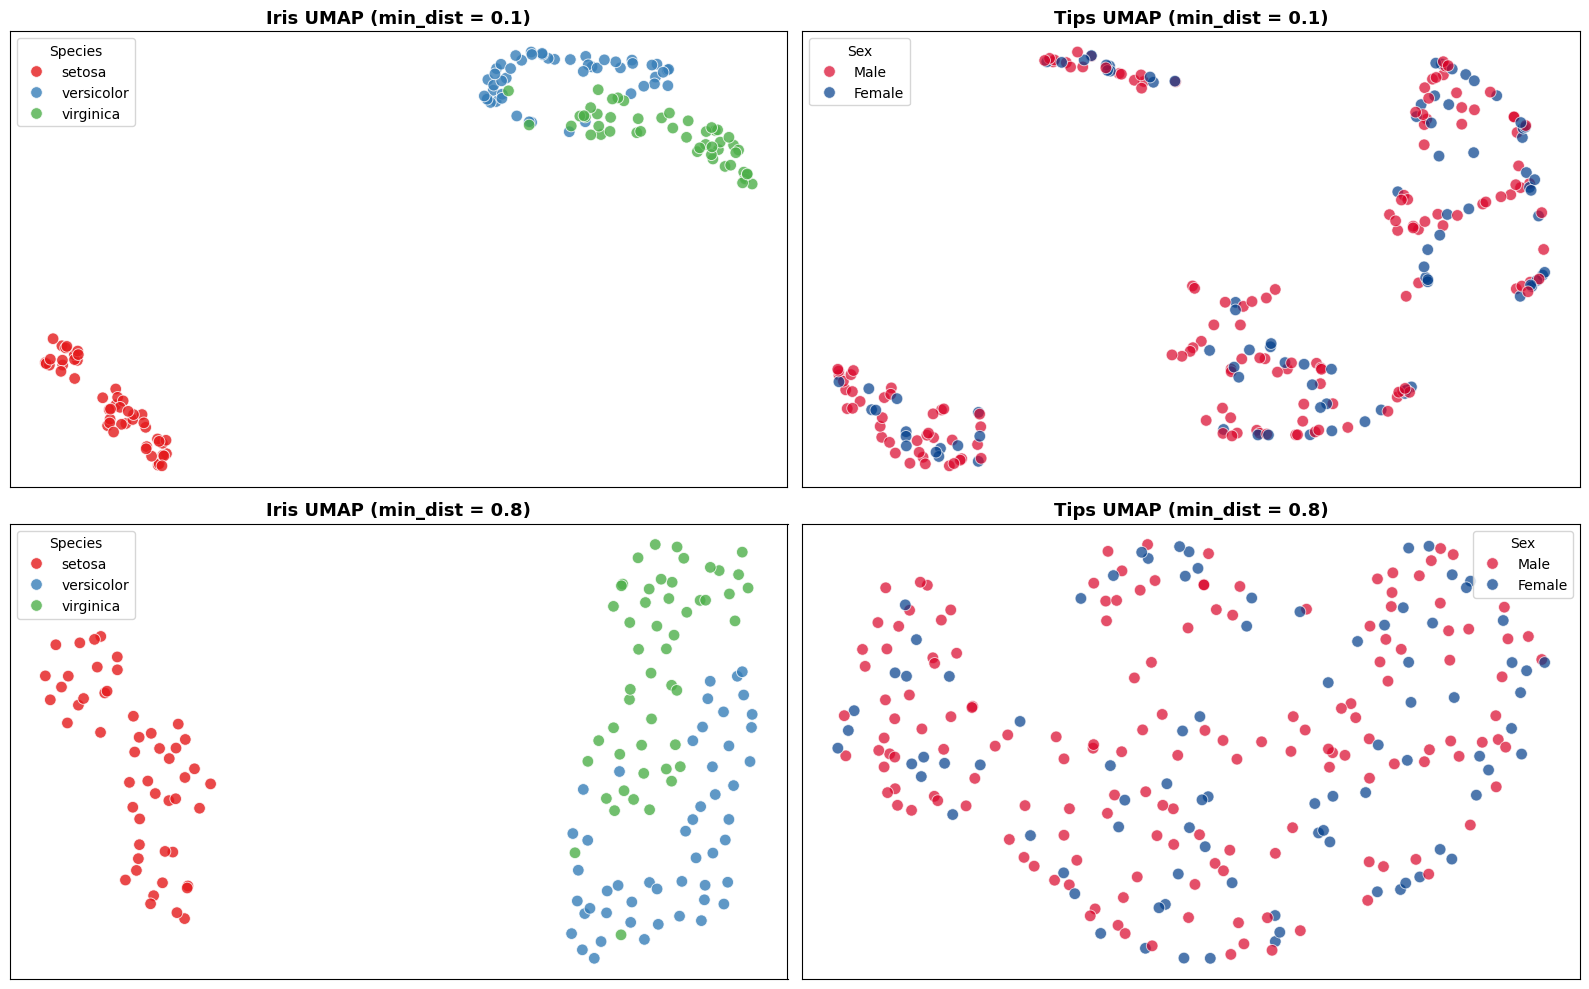

In [34]:
min_distances = [0.1, 0.8]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plt.subplots_adjust(hspace=0.3)

for i, md in enumerate(min_distances):
    # 1. Fit Manifolds
    umap_iris = umap.UMAP(n_neighbors=15, min_dist=md, random_state=42, n_jobs=1)
    X_ir_umap = umap_iris.fit_transform(X_iris_scaled)
    
    umap_tips = umap.UMAP(n_neighbors=15, min_dist=md, random_state=42, n_jobs=1)
    X_tp_umap = umap_tips.fit_transform(X_tips_scaled)
    
    # 2. Plot Iris 
    sns.scatterplot(
        x=X_ir_umap[:, 0], y=X_ir_umap[:, 1], 
        hue=y_iris, ax=axes[i, 0], palette='Set1', s=70, alpha=0.8
    )
    axes[i, 0].set_title(f"Iris UMAP (min_dist = {md})", fontweight='bold', fontsize=13)
    axes[i, 0].set_xticks([]) 
    axes[i, 0].set_yticks([])
    axes[i, 0].legend(title='Species')
    
    # 3. Plot Tips 
    sns.scatterplot(
        x=X_tp_umap[:, 0], y=X_tp_umap[:, 1], 
        hue=y_tips, ax=axes[i, 1], palette=['#d90429', '#023e8a'], s=70, alpha=0.7
    )
    axes[i, 1].set_title(f"Tips UMAP (min_dist = {md})", fontweight='bold', fontsize=13)
    axes[i, 1].set_xticks([])
    axes[i, 1].set_yticks([])
    axes[i, 1].legend(title='Sex')

plt.tight_layout()
plt.show()

Notice how the top and bottom rows look different.

* When min_dist is 0.1 (top row), UMAP squeezes the Iris species into tight, dense clusters. When min_dist is 0.8 (bottom row), UMAP spreads the same data out into looser, more open groups.
* If you look at the Tips dataset on the right, it does not matter whether the data is packed tightly or spread out. It also doesn't matter whether we use PCA, LDA, t-SNE, or UMAP. The red and blue dots always stay mixed within each cluster.

### **Task 5**